In [1]:
import pandas as pd

county_need = pd.read_csv("../data/processed/county_need_2024.csv")
cms24_small = pd.read_csv("../data/processed/cms24_county_small.csv")

In [2]:
county_need["CountyFIPS"] = county_need["CountyFIPS"].astype(str).str.zfill(5)

cms24_small["BENE_GEO_CD"] = (
    cms24_small["BENE_GEO_CD"]
    .astype(int)
    .astype(str)
    .str.zfill(5)
)

In [3]:
analysis_df = county_need.merge(
    cms24_small,
    left_on="CountyFIPS",
    right_on="BENE_GEO_CD",
    how="inner"
)

In [4]:
analysis_df.shape

(3142, 45)

In [5]:
analysis_df.isna().sum().sort_values(ascending=False).head(15)

PQI08_CHF_AGE_GE_75               3142
PQI08_CHF_AGE_65_74               3142
PQI07_HYPRTNSN_AGE_GE_75          3142
PQI07_HYPRTNSN_AGE_65_74          3142
PQI05_COPD_ASTHMA_AGE_GE_75       3142
PQI05_COPD_ASTHMA_AGE_65_74       3142
PQI03_DBTS_AGE_GE_75              3142
PQI03_DBTS_AGE_65_74              3142
IP_MDCR_STDZD_PYMT_PC                0
EM_EVNTS_PER_1000_BENES              0
FQHC_RHC_VISITS_PER_1000_BENES       0
TESTS_EVNTS_PER_1000_BENES           0
IMGNG_EVNTS_PER_1000_BENES           0
PRCDR_EVNTS_PER_1000_BENES           0
TESTS_MDCR_STDZD_PYMT_PC             0
dtype: int64

In [6]:
analysis_df[
    [
        "NeedScore",
        "TOT_MDCR_STDZD_PYMT_PC",
        "ACUTE_HOSP_READMSN_PCT",
        "ER_VISITS_PER_1000_BENES",
        "IP_CVRD_STAYS_PER_1000_BENES",
        "OP_VISITS_PER_1000_BENES",
        "FQHC_RHC_VISITS_PER_1000_BENES"
    ]
].describe().T

,count,mean,std,min,25%,50%,75%,max
NeedScore,3142.0,1.346174,2.070306,-4.492298,-0.085369,1.130676,2.841329,9.314433


In [7]:
analysis_df = analysis_df.dropna(axis=1, how="all")

In [9]:
analysis_df["ER_VISITS_PER_1000_BENES"].dtype

<StringDtype(storage='python', na_value=nan)>

In [10]:
numeric_cols = [
    "TOT_MDCR_STDZD_PYMT_PC",
    "ACUTE_HOSP_READMSN_PCT",
    "ER_VISITS_PER_1000_BENES",
    "IP_CVRD_STAYS_PER_1000_BENES",
    "OP_VISITS_PER_1000_BENES",
    "FQHC_RHC_VISITS_PER_1000_BENES",
    "TESTS_EVNTS_PER_1000_BENES",
    "IMGNG_EVNTS_PER_1000_BENES",
    "PRCDR_EVNTS_PER_1000_BENES"
]

for col in numeric_cols:
    analysis_df[col] = pd.to_numeric(
        analysis_df[col].str.replace(",", "", regex=False),
        errors="coerce"
    )

In [11]:
analysis_df[numeric_cols].dtypes

TOT_MDCR_STDZD_PYMT_PC            float64
ACUTE_HOSP_READMSN_PCT            float64
ER_VISITS_PER_1000_BENES          float64
IP_CVRD_STAYS_PER_1000_BENES      float64
OP_VISITS_PER_1000_BENES          float64
FQHC_RHC_VISITS_PER_1000_BENES    float64
TESTS_EVNTS_PER_1000_BENES        float64
IMGNG_EVNTS_PER_1000_BENES        float64
PRCDR_EVNTS_PER_1000_BENES        float64
dtype: object

In [12]:
analysis_df[numeric_cols].isna().sum()

TOT_MDCR_STDZD_PYMT_PC              1
ACUTE_HOSP_READMSN_PCT            145
ER_VISITS_PER_1000_BENES            2
IP_CVRD_STAYS_PER_1000_BENES       12
OP_VISITS_PER_1000_BENES            1
FQHC_RHC_VISITS_PER_1000_BENES     26
TESTS_EVNTS_PER_1000_BENES          2
IMGNG_EVNTS_PER_1000_BENES          2
PRCDR_EVNTS_PER_1000_BENES          3
dtype: int64

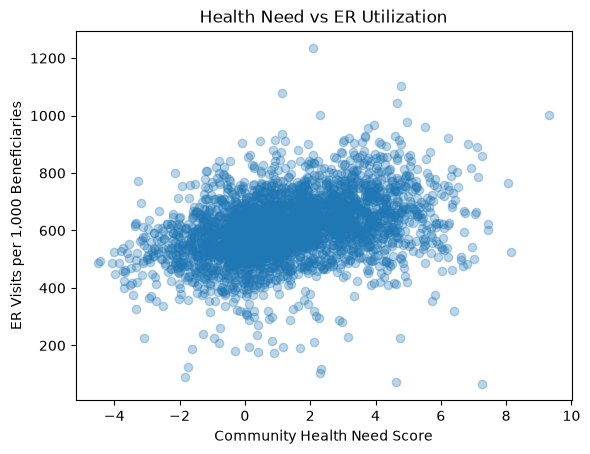

In [13]:
import matplotlib.pyplot as plt

plt.scatter(
    analysis_df["NeedScore"],
    analysis_df["ER_VISITS_PER_1000_BENES"],
    alpha=0.3
)

plt.xlabel("Community Health Need Score")
plt.ylabel("ER Visits per 1,000 Beneficiaries")
plt.title("Health Need vs ER Utilization")
plt.show()

In [14]:
analysis_df[
    ["NeedScore", "ER_VISITS_PER_1000_BENES"]
].corr()

,NeedScore,ER_VISITS_PER_1000_BENES
NeedScore,1.000000,0.351837
ER_VISITS_PER_1000_BENES,0.351837,1.000000


In [15]:
analysis_df[
    [
        "NeedScore",
        "ER_VISITS_PER_1000_BENES",
        "ACUTE_HOSP_READMSN_PCT",
        "IP_CVRD_STAYS_PER_1000_BENES",
        "TOT_MDCR_STDZD_PYMT_PC"
    ]
].corr()

,NeedScore,ER_VISITS_PER_1000_BENES,ACUTE_HOSP_READMSN_PCT,IP_CVRD_STAYS_PER_1000_BENES,TOT_MDCR_STDZD_PYMT_PC
NeedScore,1.000000,0.351837,0.239104,0.397778,0.300311
ER_VISITS_PER_1000_BENES,0.351837,1.000000,0.337359,0.514198,0.390206
ACUTE_HOSP_READMSN_PCT,0.239104,0.337359,1.000000,0.613938,0.318445
IP_CVRD_STAYS_PER_1000_BENES,0.397778,0.514198,0.613938,1.000000,0.666122
TOT_MDCR_STDZD_PYMT_PC,0.300311,0.390206,0.318445,0.666122,1.000000


In [16]:
from sklearn.linear_model import LinearRegression

model_df = analysis_df[
    ["NeedScore", "ER_VISITS_PER_1000_BENES"]
].dropna()

X = model_df[["NeedScore"]]
y = model_df["ER_VISITS_PER_1000_BENES"]

model = LinearRegression()
model.fit(X, y)

model_df["Predicted_ER"] = model.predict(X)
model_df["ER_Residual"] = y - model_df["Predicted_ER"]